# Quantum Funding Geographic Bubble Chart — Matplotlib Atlas Edition

This Colab notebook draws the funding infographic with **pure Matplotlib**. It uses a faceted low-poly world silhouette, translucent regional halos, country-level bubbles, source-aware caveats, a bubble-size key, regional subtotals, a world total, and a text signature.

Run the notebook from top to bottom. The setup cell fetches the current `trunk` data into `/content/mit-prox-rd`; the chart itself is rendered from Matplotlib patches and annotations, with no Cartopy or GeoPandas dependency.

**Data note:** the CSV intentionally distinguishes annual/annualized country figures from cumulative aggregates and missing comparable totals. China is shown in the same bubble style as other countries, but its cumulative estimate is flagged and excluded from annual totals.

In [ ]:
from pathlib import Path
import os
import subprocess

PROJECT_DIR = Path("/content/mit-prox-rd")
REPO_URL = "https://github.com/qimono-repos/mit-prox-rd.git"

# Clone trunk on first run; refresh it on later runs.
if not (PROJECT_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", "--branch", "trunk", "--single-branch", REPO_URL, str(PROJECT_DIR)],
        check=True,
    )
else:
    subprocess.run(["git", "-C", str(PROJECT_DIR), "fetch", "origin", "trunk"], check=True)
    subprocess.run(["git", "-C", str(PROJECT_DIR), "checkout", "-B", "trunk", "FETCH_HEAD"], check=True)

os.chdir(PROJECT_DIR)
print("Project directory:", Path.cwd())
print("CSV exists:", Path("assets/quantum_funding_updated.csv").exists())

## 1. Imports and Data Loading

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon
import numpy as np
from pathlib import Path

csv_path = Path("assets/quantum_funding_updated.csv")
if not csv_path.is_file():
    raise FileNotFoundError(f"CSV not found: {csv_path.resolve()}")

df = pd.read_csv(csv_path, encoding="utf-8-sig")
expected_columns = {"Rank", "Country / Entity", "highest confidence figure USD Millions", "Type", "ssource-link", "observations"}
missing = expected_columns.difference(df.columns)
if missing:
    raise ValueError(f"CSV is missing expected columns: {sorted(missing)}")

print(f"Loaded {len(df)} records and {len(df.columns)} columns from {csv_path}.")
display(df.head())

## 2. Configuration

Define the values used for bubble sizing and the approximate geographic coordinates.

In [12]:
values = {
    "United States": 1006,
    "Canada": 38.5,
    "Brazil": 5.5,
    "United Kingdom": 330,
    "Germany": 848,
    "Netherlands": 85,
    "Switzerland": 23,
    "Austria": 24,
    "Italy": 36,
    "India": 90,
    "South Korea": 140,
    "Japan": 241,
    "Singapore": 44,
    "Australia": None,
    "China": 15000,
}

pos = {
    "Canada": (-105, 57),
    "United States": (-99, 37),
    "Brazil": (-52, -10),
    "United Kingdom": (-3, 54),
    "Netherlands": (5, 53),
    "Germany": (11, 51),
    "Switzerland": (8, 47),
    "Austria": (14, 47),
    "Italy": (12, 42),
    "India": (79, 22),
    "South Korea": (128, 36),
    "Japan": (139, 37),
    "Singapore": (104, 1.3),
    "Australia": (134, -25),
    "China": (105, 35),
}

## 3. Generate the Chart

### 3A. Reusable low-poly world layer

This cell owns the world silhouette independently from the funding bubbles. The coastlines are hand-drawn as geographic polygon outlines, then filled with subtle triangular facets to create a quiet gray low-poly atlas. Reuse `draw_world_low_poly(ax)` in other Matplotlib charts by copying this cell and calling the function before plotting data. No image files, SVG assets, Cartopy, GeoPandas, or Shapely are required.

In [ ]:
# REUSABLE WORLD LAYER | pure Matplotlib
# Edit the coastline outlines and facet palette here without touching the funding chart.
# Coordinates are approximate longitude/latitude. This is an editorial silhouette, not a GIS basemap.

from matplotlib.patches import Polygon

WORLD_FACE = "#e4e7eb"
WORLD_EDGE = "#cbd2db"
WORLD_FACET_LIGHT = "#edf0f3"
WORLD_FACET_DARK = "#d9dfe6"

# Coastline-like outlines: denser points improve recognition while keeping the low-poly style.
WORLD_CONTINENTS = {
    "north_america": [
        (-168,69),(-158,72),(-148,70),(-140,66),(-132,62),(-127,55),(-123,49),
        (-117,44),(-112,34),(-106,31),(-98,25),(-91,19),(-83,9),(-78,8),
        (-80,17),(-75,24),(-80,31),(-75,36),(-67,44),(-60,51),(-58,58),
        (-72,63),(-88,66),(-105,72),(-126,73),(-145,72),(-158,70)
    ],
    "greenland": [
        (-54,83),(-39,82),(-24,76),(-30,68),(-42,60),(-53,59),(-61,66),(-60,75)
    ],
    "central_america": [
        (-106,31),(-97,23),(-91,18),(-86,13),(-82,9),(-78,8),(-81,17),(-87,21),(-94,27)
    ],
    "south_america": [
        (-81,12),(-74,10),(-68,7),(-61,3),(-52,-2),(-44,-8),(-38,-15),
        (-43,-23),(-49,-32),(-54,-41),(-61,-54),(-67,-48),(-71,-35),
        (-75,-20),(-79,-5)
    ],
    "europe_asia": [
        (-10,36),(-10,44),(-5,50),(2,55),(8,59),(18,61),(27,67),(39,69),
        (51,65),(61,62),(73,61),(86,58),(98,56),(111,53),(124,50),(137,48),
        (151,45),(163,39),(170,31),(160,23),(148,18),(139,10),(127,5),
        (116,8),(108,15),(98,20),(87,22),(77,28),(68,34),(58,39),(49,37),
        (40,34),(32,30),(27,23),(19,20),(11,28),(4,35),(-2,36)
    ],
    "africa": [
        (-17,36),(-5,37),(9,35),(22,31),(33,21),(39,9),(35,-5),(29,-17),
        (21,-34),(12,-35),(4,-27),(-2,-12),(-9,3),(-15,18)
    ],
    "arabian_peninsula": [
        (34,30),(48,28),(57,17),(51,12),(43,12),(39,20)
    ],
    "india": [
        (67,28),(79,30),(89,23),(85,12),(78,6),(73,16)
    ],
    "southeast_asia": [
        (93,21),(105,20),(116,12),(122,4),(114,-7),(105,1),(99,9)
    ],
    "japan": [
        (130,45),(139,43),(145,37),(142,32),(136,34),(132,39)
    ],
    "australia": [
        (112,-11),(117,-18),(123,-20),(130,-16),(137,-13),(145,-16),
        (153,-25),(148,-38),(137,-43),(125,-39),(116,-31)
    ],
    "madagascar": [(49,-12),(51,-17),(49,-25),(46,-21)],
    "british_isles": [(-8,59),(-3,58),(0,53),(-4,50),(-7,54)],
    "sri_lanka": [(79,9),(82,7),(81,5),(79,7)],
    "new_zealand": [(172,-35),(178,-41),(174,-46),(169,-42)],
}

# Small inset facets are deliberately contained within broad land silhouettes.
# They add depth without competing with the funding circles.
WORLD_FACETS = [
    [(-157,66),(-137,64),(-145,53)], [(-137,64),(-122,55),(-145,53)],
    [(-145,53),(-122,55),(-112,39)], [(-122,55),(-105,49),(-112,39)],
    [(-112,39),(-105,49),(-91,34)], [(-105,49),(-84,45),(-91,34)],
    [(-91,34),(-84,45),(-80,31)], [(-84,45),(-67,44),(-80,31)],
    [(-99,24),(-83,20),(-91,12)], [(-74,8),(-56,1),(-64,-15)],
    [(-56,1),(-44,-8),(-51,-24)], [(-64,-15),(-51,-24),(-61,-43)],
    [(-5,53),(12,59),(8,47)], [(12,59),(27,55),(28,45)],
    [(8,47),(28,45),(20,35)], [(28,45),(40,34),(48,38)],
    [(40,34),(48,38),(57,28)], [(48,38),(61,45),(73,28)],
    [(61,45),(78,48),(73,28)], [(78,48),(98,45),(93,29)],
    [(98,45),(118,42),(112,28)], [(118,42),(143,38),(130,23)],
    [(93,29),(112,28),(108,15)], [(112,28),(130,23),(122,8)],
    [(-6,30),(11,27),(4,10)], [(11,27),(25,18),(20,2)],
    [(4,10),(20,2),(12,-19)], [(20,2),(31,-6),(21,-25)],
    [(118,-20),(133,-16),(130,-29)], [(133,-16),(147,-25),(137,-38)],
]

def draw_world_low_poly(ax, *, zorder=1, show_facets=True):
    """Draw a reusable gray low-poly world silhouette on an existing Matplotlib axis.

    Facets are clipped to the land silhouettes, so no triangular shards spill into
    the oceans. Call this before adding region halos and data bubbles.
    """
    land_patches = []
    island_names = {"greenland", "madagascar", "british_isles", "sri_lanka", "new_zealand", "japan"}

    # Draw land silhouettes first and keep their patch objects for facet clipping.
    for name, points in WORLD_CONTINENTS.items():
        is_island = name in island_names
        patch = Polygon(
            points, closed=True,
            facecolor=WORLD_FACE if not is_island else "#e8ebef",
            edgecolor=WORLD_EDGE, linewidth=0.55 if is_island else 0.8,
            joinstyle="round", antialiased=True, zorder=zorder
        )
        ax.add_patch(patch)
        land_patches.append(patch)

    if show_facets:
        # Each triangle is clipped independently to every land patch. This keeps
        # the faceted texture inside coastlines while preserving a reusable,
        # dependency-free Matplotlib implementation.
        for i, points in enumerate(WORLD_FACETS):
            for land_patch in land_patches:
                facet = Polygon(
                    points, closed=True,
                    facecolor=WORLD_FACET_LIGHT if i % 2 == 0 else WORLD_FACET_DARK,
                    edgecolor="none", alpha=0.62, antialiased=True,
                    zorder=zorder + 0.08
                )
                facet.set_clip_path(land_patch)
                ax.add_patch(facet)

    return ax


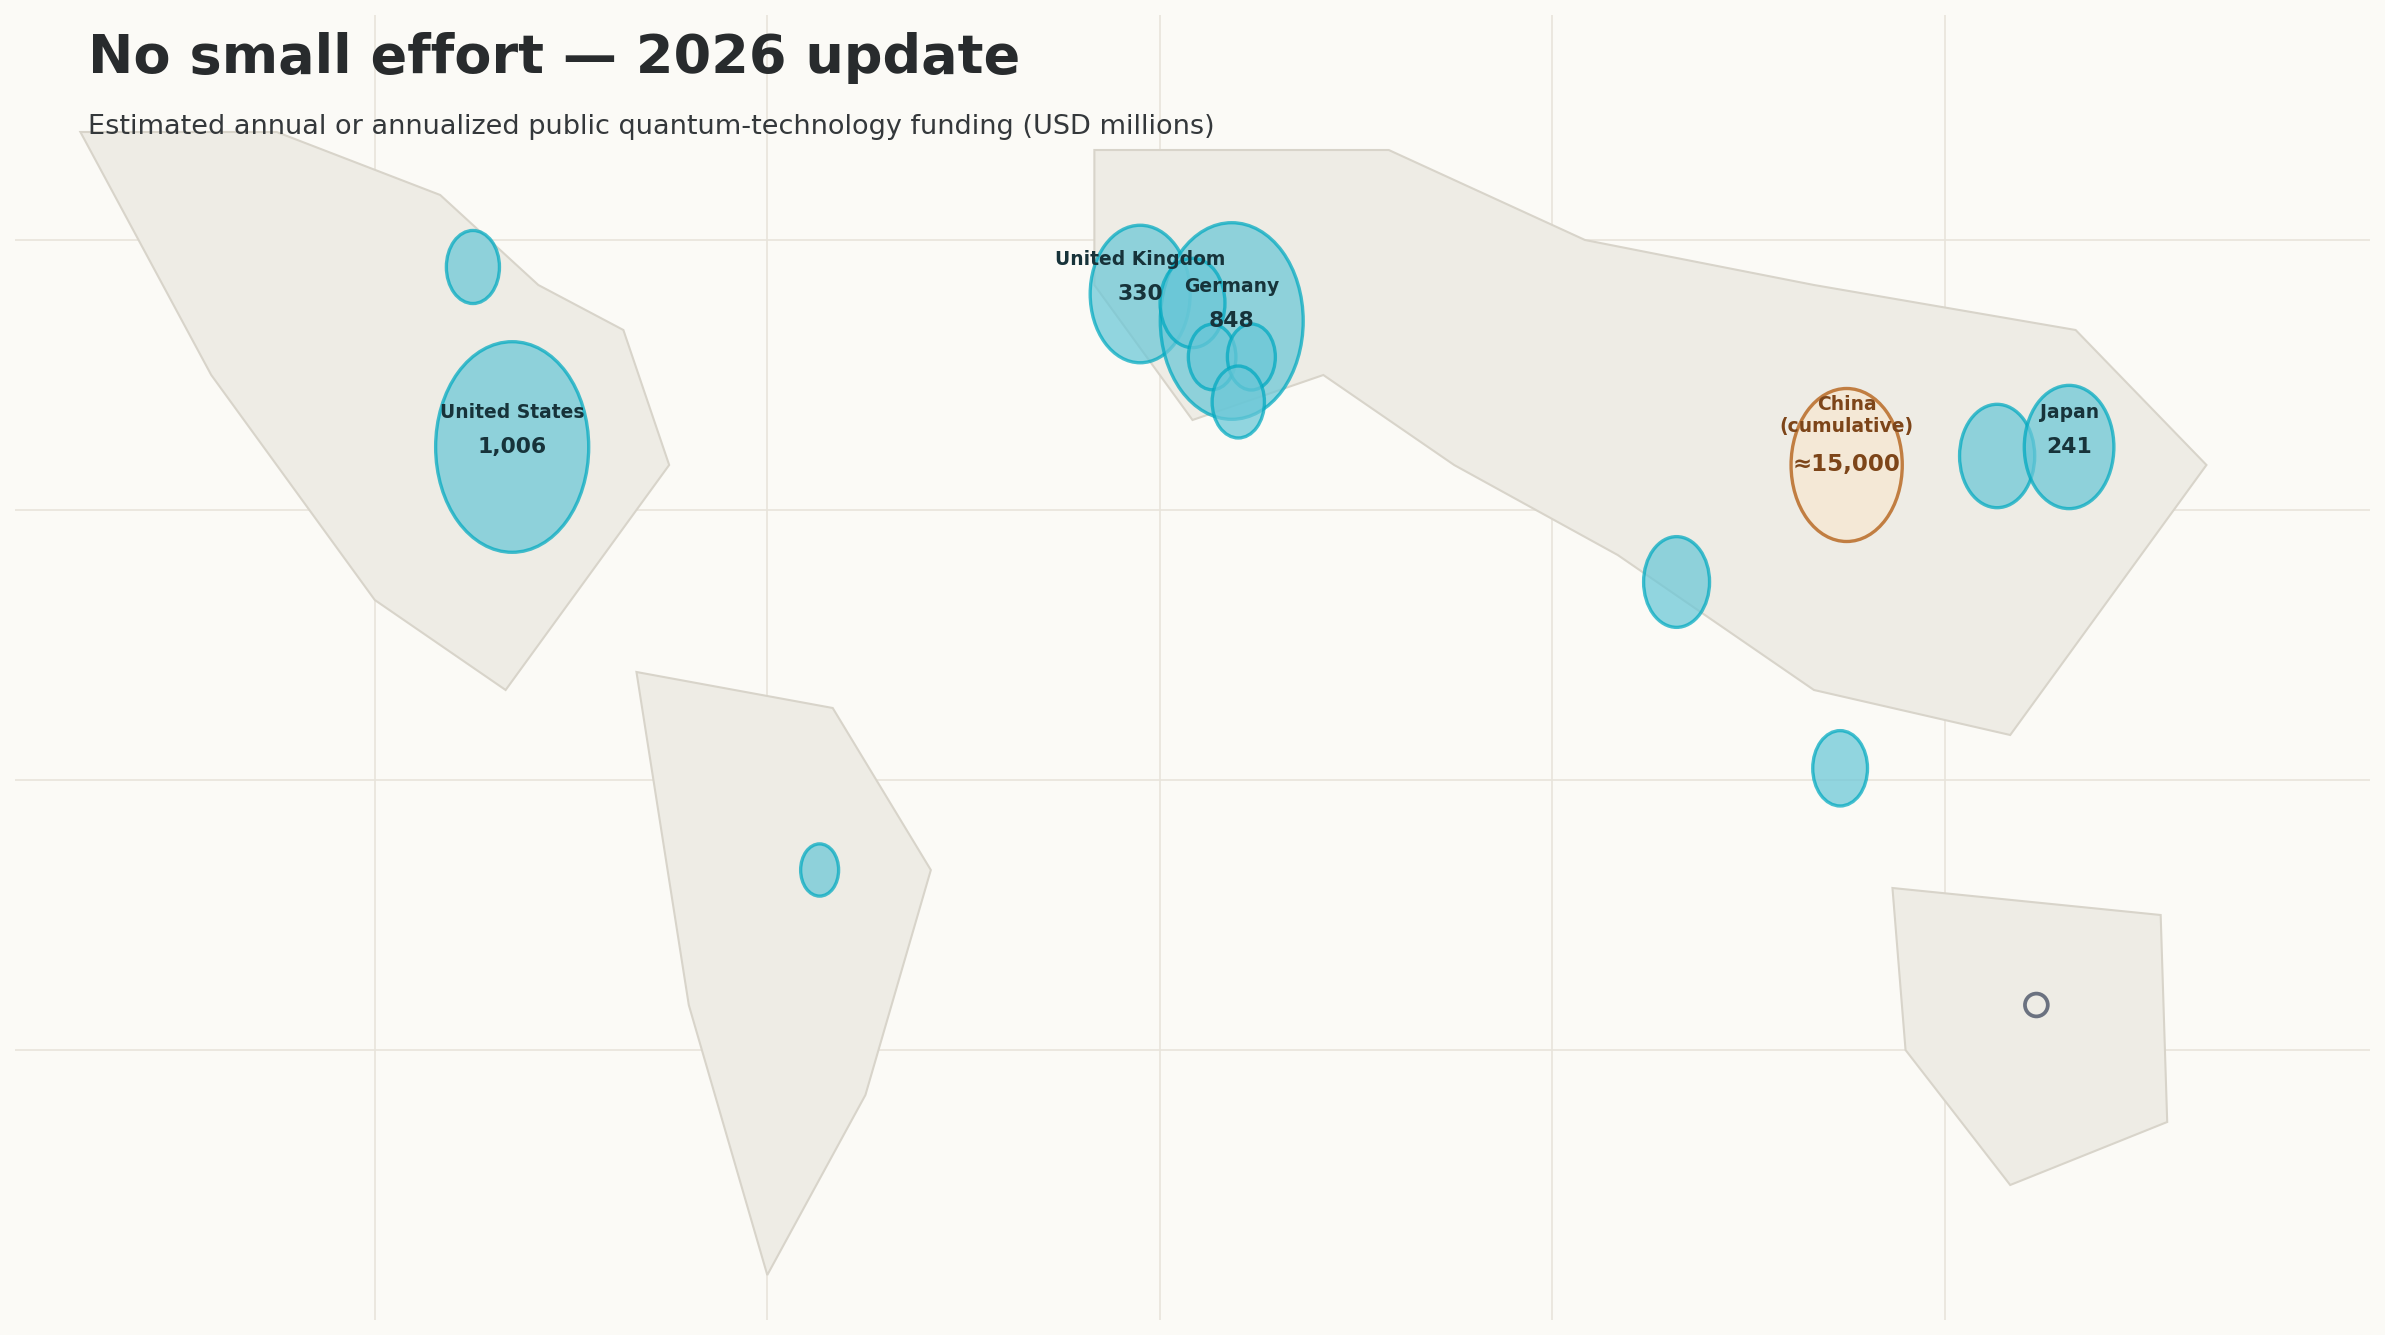

In [15]:
# Publication-style geographic funding infographic, pure Matplotlib (no Cartopy/GeoPandas).
# Country figures are loaded from the CSV. China uses the same bubble style as other countries;
# its cumulative estimate is explicitly caveated in the notes and is excluded from annual totals.

import math
from matplotlib.patches import Circle, Polygon, Ellipse
from matplotlib.lines import Line2D

# --- Data selection and region membership ---
name_col = "Country / Entity"
value_col = "highest confidence figure USD Millions"
type_col = "Type"
obs_col = "observations"

data = df.copy()
data[value_col] = pd.to_numeric(data[value_col], errors="coerce")

# The US has separate FY2023/FY2024/FY2025 rows: use FY2024 enacted for this snapshot.
us_rows = data[data[name_col].eq("United States")]
us_2024 = us_rows[us_rows[type_col].astype(str).str.contains("FY2024 enacted", case=False, na=False)]
selected = data[~data[name_col].eq("United States")].copy()
if not us_2024.empty:
    selected = pd.concat([selected, us_2024.iloc[[0]]], ignore_index=True)
else:
    selected = pd.concat([selected, us_rows.iloc[[0]]], ignore_index=True)

# Keep country rows only; regional/cumulative aggregates must not be counted as countries.
excluded_entities = {
    "Confirmed global total", "Europe (confirmed)", "Asia-Pacific (confirmed)",
    "Americas (confirmed)", "European Union (Flagship)"
}
selected = selected[~selected[name_col].isin(excluded_entities)]
country_values = dict(zip(selected[name_col], selected[value_col]))

regions = {
    "Americas": ["United States", "Canada", "Brazil"],
    "Europe": ["United Kingdom", "Germany", "Netherlands", "Switzerland", "Austria", "Italy"],
    "Asia": ["Russia", "China", "India", "Japan", "South Korea"],
    "APAC": ["Singapore", "Australia"],
}
region_colors = {
    "Americas": "#159bd7",
    "Europe": "#f04462",
    "Asia": "#f28b20",
    "APAC": "#8050d7",
}
positions = {
    "Canada": (-105, 56), "United States": (-99, 37), "Brazil": (-52, -10),
    "United Kingdom": (-3, 54), "Netherlands": (5, 53), "Germany": (11, 51),
    "Switzerland": (8, 47), "Austria": (14, 47), "Italy": (12, 42),
    "Russia": (90, 57), "India": (79, 22), "China": (105, 35),
    "Japan": (139, 37), "South Korea": (128, 36),
    "Singapore": (104, 1.3), "Australia": (134, -25),
}
# Label offsets keep dense European labels legible and make missing data explicit.
label_offsets = {
    "United States": (-22, 3), "Canada": (12, 7), "Brazil": (10, -2),
    "United Kingdom": (-22, 9), "Netherlands": (-12, 14), "Germany": (13, 8),
    "Switzerland": (13, -3), "Austria": (13, -10), "Italy": (-13, -11),
    "Russia": (9, 8), "India": (5, -10), "China": (11, 0),
    "Japan": (8, 7), "South Korea": (11, -6), "Singapore": (8, 0),
    "Australia": (11, 0),
}

def fmt_usd_millions(value):
    if pd.isna(value):
        return "no comparable total"
    if value >= 1000:
        return f"${value/1000:.2f}B"
    return f"${value:.0f}M"

def region_total(region):
    # China is cumulative and Australia has no comparable dedicated total.
    members = [n for n in regions[region] if n != "China" and not pd.isna(country_values.get(n, np.nan))]
    return sum(float(country_values[n]) for n in members)

# --- Canvas and editorial palette ---
fig = plt.figure(figsize=(19, 12), dpi=170, facecolor="#fbfaf7")
ax = fig.add_axes([0.035, 0.19, 0.93, 0.63])
ax.set_facecolor("#fbfaf7")
ink, muted = "#111b3c", "#59647b"
ax.set_xlim(-178, 185)
ax.set_ylim(-59, 83)
ax.axis("off")

# Soft coordinate grid
for lon in [-120, -60, 0, 60, 120]:
    ax.axvline(lon, color="#e8e9ee", lw=0.65, zorder=0)
for lat in [-30, 0, 30, 60]:
    ax.axhline(lat, color="#e8e9ee", lw=0.65, zorder=0)

# Reusable world layer: see section 3A for the low-poly geometry and drawing function.
draw_world_low_poly(ax)

# Translucent regional halos provide the large "continent bubble" layer.
region_halos = {
    "Americas": (-104, 30, 76, 93),
    "Europe": (17, 43, 64, 67),
    "Asia": (94, 36, 104, 78),
    "APAC": (132, -19, 63, 51),
}
for region, (cx, cy, w, h) in region_halos.items():
    ax.add_patch(Ellipse((cx, cy), width=w, height=h,
                         facecolor=region_colors[region], edgecolor=region_colors[region],
                         linewidth=1.4, alpha=0.105, zorder=1.5))

# Region headings and annual/annualized totals. China is deliberately excluded.
region_heading_positions = {
    "Americas": (-159, 66), "Europe": (-29, 73), "Asia": (111, 72), "APAC": (151, 0)
}
for region, (tx, ty) in region_heading_positions.items():
    total = region_total(region)
    ax.text(tx, ty, region, color=region_colors[region], fontsize=17,
            fontweight="bold", ha="left", va="center", zorder=7)
    ax.text(tx, ty-5.1, fmt_usd_millions(total), color=region_colors[region],
            fontsize=15, fontweight="bold", ha="left", va="center", zorder=7)
    ax.text(tx, ty-8.6, "listed countries" + (", excl. China" if region == "Asia" else ""),
            color=muted, fontsize=8.5, ha="left", va="center", zorder=7)

# Country bubbles use one consistent visual language, including China.
available_values = [float(v) for n, v in country_values.items()
                    if n in positions and not pd.isna(v) and n != "China"]
max_value = max(available_values) if available_values else 1
for region, countries in regions.items():
    for country in countries:
        if country not in positions:
            continue
        x, y = positions[country]
        v = country_values.get(country, np.nan)
        color = region_colors[region]
        if pd.isna(v):
            ax.scatter([x], [y], s=110, facecolors="none", edgecolors=color,
                       linewidths=1.7, zorder=5)
            dx, dy = label_offsets[country]
            ax.annotate(f"{country}\nNo comparable total recorded", (x, y),
                        xytext=(x+dx, y+dy), textcoords="data", fontsize=8.2,
                        color=ink, ha="left" if dx >= 0 else "right", va="center",
                        arrowprops=dict(arrowstyle="-", color=color, lw=0.9),
                        zorder=8)
            continue
        # Bubble area scales with value; sqrt radius gives area proportional to value.
        # China is displayed using the same rule but capped visually so it does not
        # swallow the map; its true cumulative amount is explained in the notes.
        if country == "China":
            radius = 8.3
        else:
            radius = 1.5 + 7.6 * math.sqrt(float(v) / max_value)
        ax.add_patch(Circle((x, y), radius=radius, facecolor=color,
                            edgecolor=color, linewidth=1.4, alpha=0.76, zorder=4))
        dx, dy = label_offsets[country]
        label_value = "≈$15B cumulative*" if country == "China" else fmt_usd_millions(float(v))
        # Labels for small/clustered bubbles use leader lines for legibility.
        if country in {"United Kingdom", "Netherlands", "Germany", "Switzerland", "Austria", "Italy",
                       "Canada", "Brazil", "Russia", "India", "South Korea", "Singapore", "Australia"}:
            ax.annotate(f"{country}\n{label_value}", (x, y), xytext=(x+dx, y+dy),
                        textcoords="data", fontsize=8.7, color=ink,
                        fontweight="bold", ha="left" if dx >= 0 else "right", va="center",
                        arrowprops=dict(arrowstyle="-", color=color, lw=0.9,
                                        shrinkA=1, shrinkB=2), zorder=8)
        else:
            ax.annotate(f"{country}\n{label_value}", (x, y), xytext=(x+dx, y+dy),
                        textcoords="data", fontsize=9.4, color=ink,
                        fontweight="bold", ha="left" if dx >= 0 else "right", va="center",
                        arrowprops=dict(arrowstyle="-", color=color, lw=1.0,
                                        shrinkA=1, shrinkB=2), zorder=8)

# --- Header, scale key, totals, regional legend, source and caveats ---
fig.text(0.045, 0.945, "ESTIMATED PUBLIC FUNDING FOR QUANTUM TECHNOLOGIES",
         fontsize=23, fontweight="bold", color=ink, ha="left")
fig.text(0.045, 0.908, "2026 snapshot", fontsize=20, fontweight="bold",
         color=ink, ha="left")
fig.text(0.045, 0.878, "Estimated annual or annualized public funding (USD millions)",
         fontsize=12.5, color=muted, ha="left")
fig.text(0.045, 0.855, "Multi-year budgets annualized where possible; figures are approximate.",
         fontsize=10, color=muted, ha="left")

# Bubble-size key, using illustrative annual funding values.
legend_ax = fig.add_axes([0.79, 0.845, 0.17, 0.12])
legend_ax.set_xlim(0, 10); legend_ax.set_ylim(0, 10); legend_ax.axis("off")
legend_ax.text(0.0, 9.5, "Bubble size guide", fontsize=9, color=muted, weight="bold")
for r, label, yy in [(2.25, "$1B", 6.6), (1.55, "$250M", 3.6), (0.85, "$50M", 1.3)]:
    legend_ax.add_patch(Circle((3.0, yy), r, facecolor="none", edgecolor="#7d8798", lw=0.9))
    legend_ax.text(6.0, yy, label, fontsize=8.5, color=muted, va="center")

# World total is the sum of listed annual/annualized country figures, excluding China.
listed_annual_total = sum(
    float(country_values[n]) for region, members in regions.items() for n in members
    if n != "China" and not pd.isna(country_values.get(n, np.nan))
)
fig.text(0.045, 0.145, "WORLD TOTAL", fontsize=10, color=muted, weight="bold")
fig.text(0.045, 0.108, f"≈ ${listed_annual_total/1000:.2f}B per year",
         fontsize=22, color=ink, weight="bold")
fig.text(0.045, 0.083, "Sum of listed annual / annualized country figures; China excluded.",
         fontsize=8.5, color=muted)

# Region legend doubles as a quick comparison of the regional subtotals.
legend_y = 0.145
legend_xs = [0.36, 0.49, 0.62, 0.75]
for (region, color), x in zip(region_colors.items(), legend_xs):
    fig.patches.append(Circle((x, legend_y), radius=0.008, transform=fig.transFigure,
                              facecolor=color, edgecolor=color, alpha=0.85))
    fig.text(x+0.014, legend_y+0.006, region, fontsize=9, color=ink, weight="bold",
             ha="left", va="center")
    fig.text(x+0.014, legend_y-0.018, fmt_usd_millions(region_total(region)),
             fontsize=9, color=color, weight="bold", ha="left", va="center")

fig.text(0.045, 0.045,
         "Sources: U.S. NQI Annual Report FY2025; McKinsey quantum landscape; national strategy and ministry sources; The Quantum Insider.",
         fontsize=7.8, color=muted, ha="left")
fig.text(0.045, 0.027,
         "Notes: multi-year commitments are annualized estimates, not necessarily annual appropriations or actual expenditure; regional sums include only listed country rows.",
         fontsize=7.4, color=muted, ha="left")
fig.text(0.58, 0.027,
         "China: ~US$15B cumulative estimate through 2024, high uncertainty; not comparable to annual figures and excluded from totals.",
         fontsize=7.4, color=muted, ha="left")
fig.text(0.955, 0.073, "Albert Gruning", fontsize=17, color="#242b3b",
         fontstyle="italic", ha="right")
fig.text(0.955, 0.052, "R&D tech specialist at Qimono (TM)", fontsize=7.7,
         color=muted, ha="right")
fig.text(0.955, 0.035, "Original report for MIT", fontsize=7.7,
         color=muted, ha="right")

plt.show()


## 4. Notes

- U.S. figure is FY2024 enacted.
- Multi-year programs are annualized estimates.
- China is a cumulative estimate with high uncertainty and is not on the same scale.
- See `REFERENCES.md` for full source list.